In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

from adjustText import adjust_text
import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
import statsmodels.api as sm
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [3]:
# config
sns.set_theme(style="ticks")
pl.Config.set_engine_affinity("streaming")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path, read_only=True)

In [11]:
query = """
    WITH v AS (
        SELECT ID_STORE, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
        FROM visits
        GROUP BY ID_STORE
    )
    SELECT 
        p.*, v.TOTAL_VISITORS AS VISITORS,
        COALESCE(CATEGORY, 'Other') AS CATEGORY, SUB_CATEGORY AS NAICS_TITLE
    FROM pois p
    JOIN v ON p.ID_STORE = v.ID_STORE
    LEFT JOIN NAICS_CATEGORIES nc ON p.NAICS_CODE = nc.NAICS_CODE
    WHERE CBSAFP = '35620'
"""
pois_dim = con.sql(query).pl()
pois_dim.head()

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,NAICS_TITLE
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",str,str
"""10896643""","""360610195005""","""35620""","""A1_NAICS-238320""","""Painting and Wall Covering Con…","""Painting and Wall Covering Con…","""225 W 106Th St""","""New York""","""NY""","""US""","""238320""","""Building Finishing Contractors""","""Painting and Wall Covering Con…",1970-01-01,2038-01-01,-73.9664,40.80088,"b""\x01\x01\x00\x00\x00Cv9\x80\xd9}R\xc0\xf2\x00\xbb?\x83fD@""",308920,474140,"""Other""","""Painting and Wall Covering Con…"
"""10932582""","""340258111021""","""35620""","""A1_NAICS-323111""","""Commercial Printing (except Sc…","""Commercial Printing (except Sc…","""271 Adelphia Rd""","""Farmingdale""","""NJ""","""US""","""323111""","""Printing and Related Support A…","""Commercial Printing (except Sc…",1970-01-01,2038-01-01,-74.200829,40.20229,"b""\x01\x01\x00\x00\x00~F3`\xda\x8cR\xc0\x14)(\xa0\xe4\x19D@""",328584,128044,"""Other""","""Commercial Printing (except Sc…"
"""10933366""","""360811163012""","""35620""","""A1_NAICS-812113""","""Nail Salons""","""Nail Salons""","""3515 146Th St""","""Flushing""","""NY""","""US""","""812113""","""Personal Care Services ""","""Nail Salons """,1970-01-01,2038-01-01,-73.821125,40.76599,"b""\x01\x01\x00\x00\x00\x05\x1c\x9dN\x8dtR\xc0*\xca\xa5\xf1\x0bbD@""",310328,25969,"""Other""","""Nail Salons """
"""10944150""","""360470824002""","""35620""","""A1_NAICS-311811""","""Retail Bakeries""","""Retail Bakeries""","""3021 Tilden Ave""","""Brooklyn""","""NY""","""US""","""311811""","""Bakeries and Tortilla Manufact…","""Retail Bakeries """,1970-01-01,2038-01-01,-73.948952,40.647018,"b""\x01\x01\x00\x00\x00\xf3>\xe9\x9f\xbb|R\xc0\x83\xf4\xb9\x7f\xd1RD@""",313135,20531,"""Other""","""Retail Bakeries """
"""10944510""","""360050130001""","""35620""","""A1_NAICS-541213""","""Tax Preparation Services""","""Tax Preparation Services""","""4027 E Tremont Ave""","""Bronx""","""NY""","""US""","""541213""","""Accounting, Tax Preparation, B…","""Tax Preparation Services """,1970-01-01,2038-01-01,-73.817141,40.819585,"b""\x01\x01\x00\x00\x00\xc1\xae\x81\x08LtR\xc0\xfad\x20*\xe8hD@""",307518,6796,"""Other""","""Tax Preparation Services """


In [16]:
pois_dim["CATEGORY"].value_counts().to_pandas(),

(                CATEGORY   count
 0                  Other  219036
 1     Museums_Historical    1407
 2  Public_Transportation     969
 3         Grocery_Stores   14277
 4            Restaurants   51492
 5                   Bars    4978
 6         Specialty_Food     762
 7                Schools     922
 8          Parks_Forests    6490
 9           Cafes_Coffee    6634,)

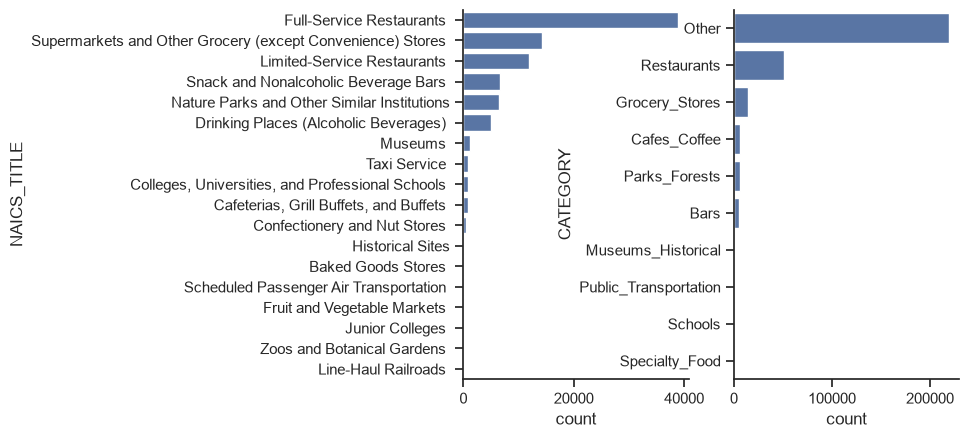

In [27]:
fig, axes = plt.subplots(1, 2)
sns.barplot(
    pois_dim["CATEGORY"].value_counts().sort("count", descending=True).to_pandas(),
    y="CATEGORY",
    x="count",
    ax=axes[1]
)
sns.barplot(
    pois_dim.filter(pl.col.CATEGORY != 'Other')["NAICS_TITLE"].value_counts().sort("count", descending=True).to_pandas(),
    y="NAICS_TITLE",
    x="count",
    ax=axes[0]
)
sns.despine()

We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

## Static segregation

In [28]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    ), filtered_pois AS (
        with x as (
            select
                v.ID_STORE, HOME_GEOID,
                SUM(VISITOR_COUNTS) AS VISITOR_COUNTS,
                COUNT(*) AS NUM_WEEKS
            from block_group_visits v
            join pois p on v.ID_STORE = p.ID_STORE
            where VISITOR_COUNTS >= 10
              and cbsafp = '35620'
            group by v.ID_STORE, HOME_GEOID
        )
        select 
            ID_STORE
        from x
        where NUM_WEEKS >= 5
          and VISITOR_COUNTS >= 100
        group by ID_STORE
        having COUNT(*) >= 10
    )
    SELECT 
        v.ID_STORE, INCOME_GROUP, 
        SUM(VISITOR_COUNTS) AS TOTAL_VISITORS, 
        COUNT(*) AS NUM_WEEKS,
        SUM(DIST * VISITOR_COUNTS) / SUM(VISITOR_COUNTS) AS AVG_DIST
    FROM block_group_visits_enhanced v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (SELECT ID_STORE FROM filtered_pois)
    GROUP BY v.ID_STORE, INCOME_GROUP
"""
poi_group_visits = con.sql(query).pl()
poi_dist = (
    poi_group_visits
        .group_by("ID_STORE")
        .agg(
            (
                (pl.col("AVG_DIST") * pl.col("TOTAL_VISITORS")).sum()
                / pl.col("TOTAL_VISITORS").sum()
            ).alias("AVG_DIST")
        )
)
poi_visits = (
    poi_group_visits
        .sort("INCOME_GROUP")
        .pivot(
            "INCOME_GROUP",
            index="ID_STORE",
            values=["TOTAL_VISITORS"],
            column_naming="combine",
        )
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
        .join(poi_dist, on="ID_STORE", how="left")
)
poi_visits.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64,f64
"""11420946""",149996,121858,113390,114439,499683,0.300182,0.243871,0.226924,0.229023,0.06691,5125.907844
"""5492475""",12591,14997,13292,42439,83319,0.151118,0.179995,0.159531,0.509356,0.345807,7164.957072
"""8781051""",48093,9313,3784,1121,62311,0.771822,0.14946,0.060728,0.01799,0.695763,2774.666337
"""10505064""",203208,112419,50011,24795,390433,0.520468,0.287934,0.128091,0.063506,0.411203,2339.152412
"""9579853""",27930,19814,33574,6642,87960,0.317531,0.225261,0.381696,0.075512,0.265636,3043.67525


In [31]:
pois = pois_dim.join(poi_visits, on="ID_STORE")
categories = pois.group_by("CATEGORY", "NAICS_TITLE").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS"),
    ((pl.col("AVG_DIST") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("AVG_DIST")
)

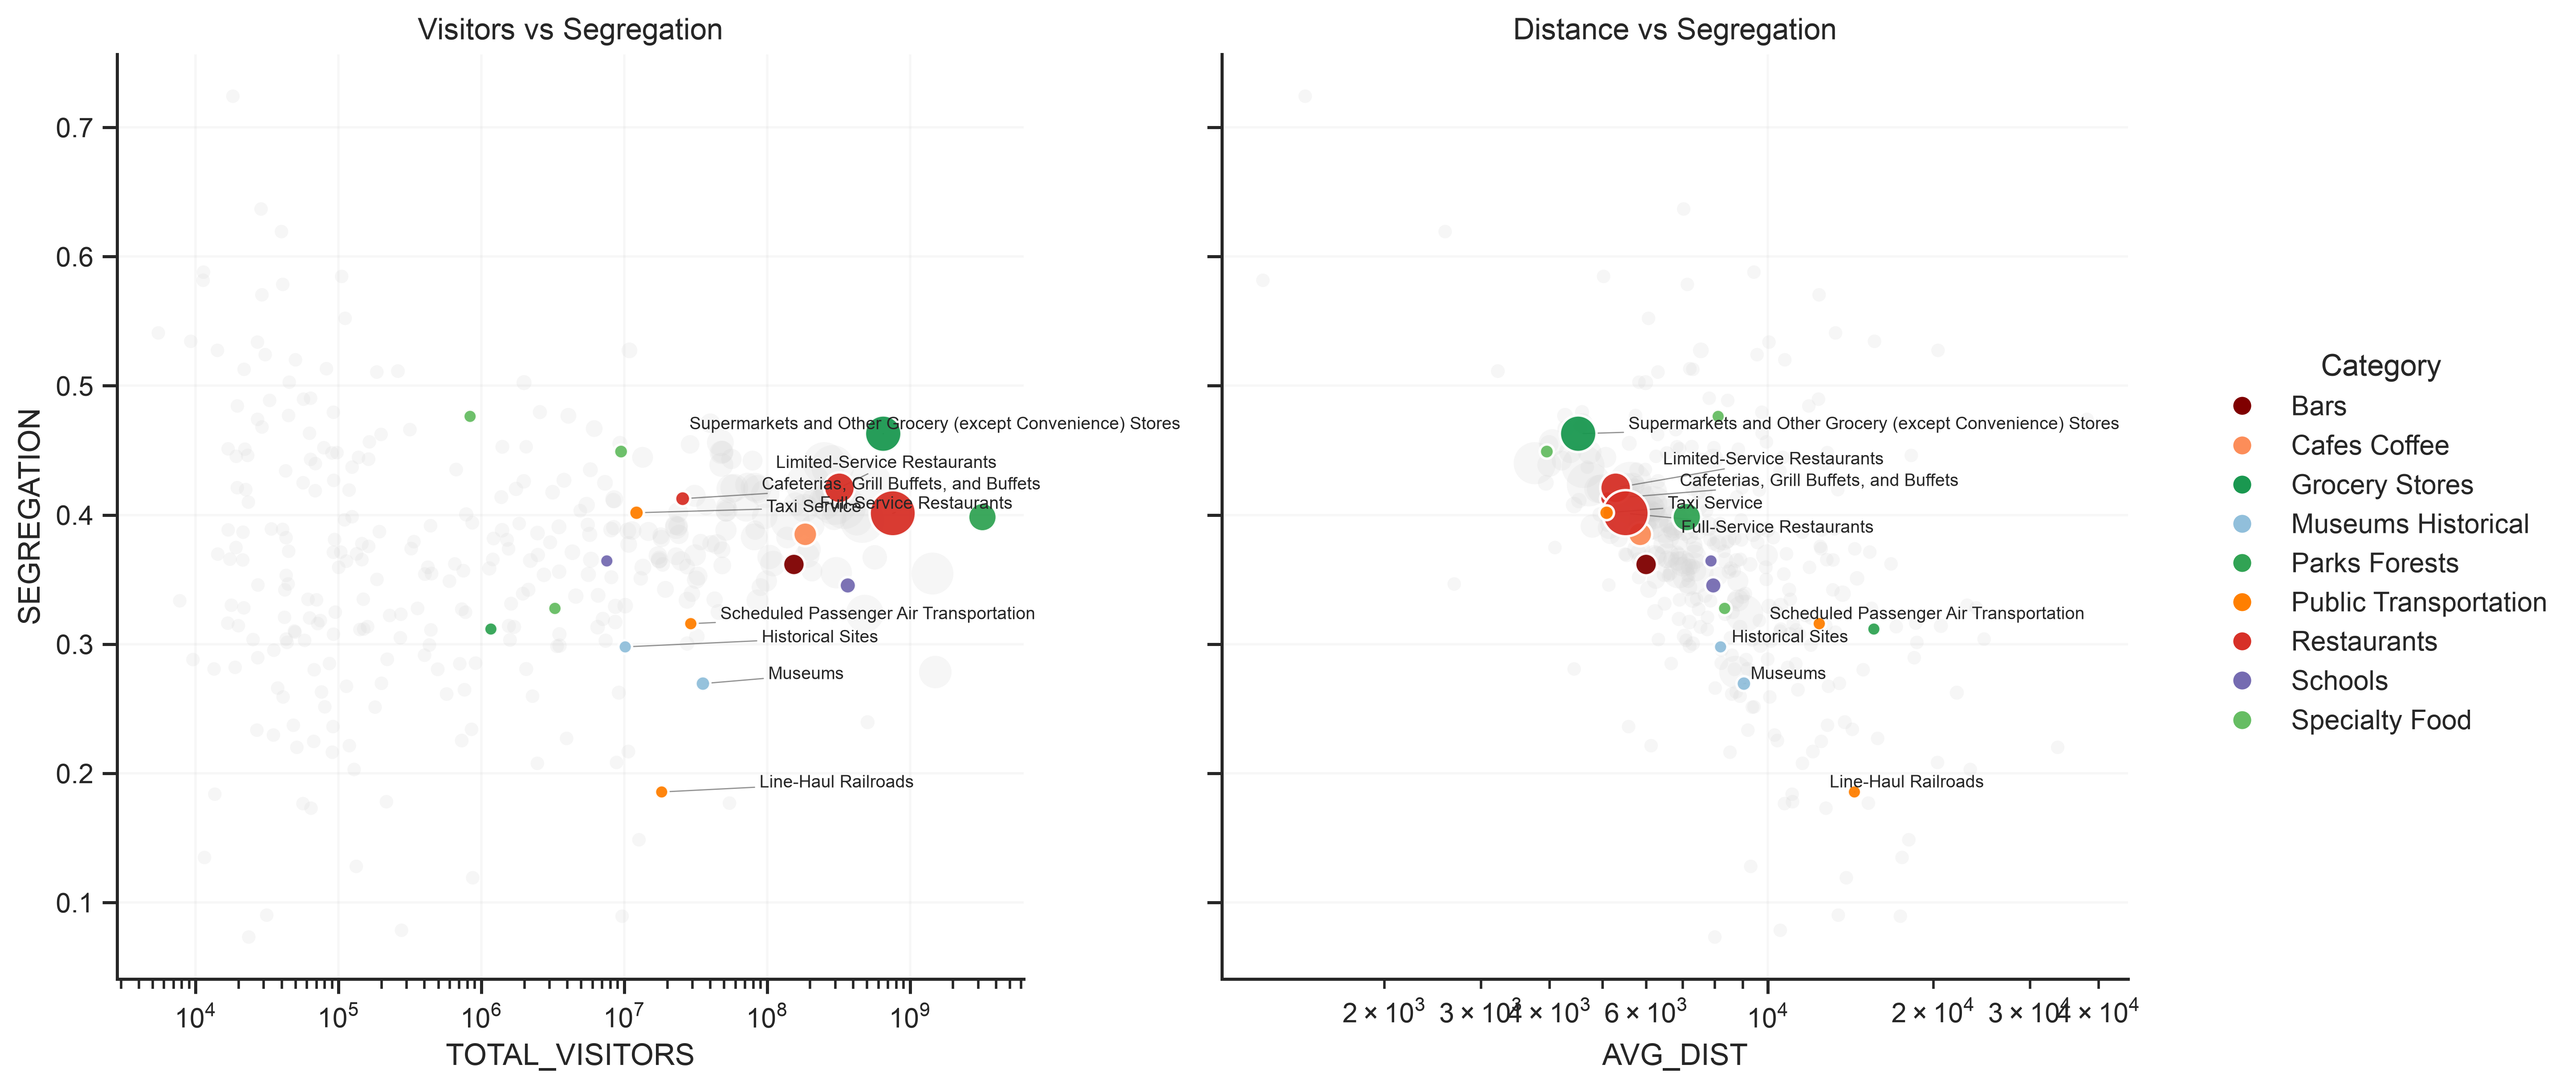

In [109]:
pdf = categories.to_pandas().copy()

# categories to label with text
label_categories = [
    "Restaurants",
    "Grocery_Stores",
    "Public_Transportation",
    "Museums_Historical",
]

palette = {
    "Other": "#d9d9d9",
    "Restaurants": "#d73027",
    "Cafes_Coffee": "#fc8d59",
    "Bars": "#7f0000",
    "Grocery_Stores": "#1a9850",
    "Specialty_Food": "#66bd63",
    "Libraries": "#4575b4",
    "Museums_Historical": "#91bfdb",
    "Parks_Forests": "#31a354",
    "Schools": "#756bb1",
    "Public_Transportation": "#ff7f00",
    "Retail": "#636363",
}

# fallback if new categories appear
for cat in pdf["CATEGORY"].unique():
    if cat not in palette:
        palette[cat] = "#4c78a8"

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 6),
    dpi=400,
    sharey=True,
    constrained_layout=True,
)

for ax, x in zip(
    axes,
    ["TOTAL_VISITORS", "AVG_DIST"],
):
    other = pdf.loc[pdf["CATEGORY"] == "Other"]
    main = pdf.loc[pdf["CATEGORY"] != "Other"]

    if len(other):
        sns.scatterplot(
            data=other,
            x=x,
            y="SEGREGATION",
            size="NUM_POIS",
            sizes=(30, 350),
            color="lightgrey",
            alpha=0.20,
            linewidth=0,
            legend=False,
            zorder=1,
            ax=ax,
        )
    sns.scatterplot(
        data=main,
        x=x,
        y="SEGREGATION",
        hue="CATEGORY",
        size="NUM_POIS",
        sizes=(30, 350),
        palette=palette,
        alpha=0.95,
        edgecolor="white",
        linewidth=1,
        legend=False,
        zorder=5,
        ax=ax,
    )

    texts = []
    label_df = main.loc[
        main["CATEGORY"].isin(label_categories)
    ]
    for _, row in label_df.iterrows():
        texts.append(
            ax.text(
                row[x],
                row["SEGREGATION"],
                row["NAICS_TITLE"],
                fontsize=7,
                zorder=20,
            )
        )
    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(
            arrowstyle="-",
            color="0.3",
            lw=0.5,
            alpha=0.6,
        ),
        expand=(1.15, 1.15),
    )

    ax.set_xscale("log")
    ax.grid(alpha=0.15)

axes[0].set_title("Visitors vs Segregation")
axes[1].set_title("Distance vs Segregation")

sns.despine()

cats = [
    c
    for c in sorted(pdf["CATEGORY"].unique())
    if c != "Other"
]

category_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="",
        markerfacecolor=palette[c],
        markeredgecolor="white",
        markeredgewidth=0.75,
        markersize=8,
        label=c.replace("_", " "),
    )
    for c in cats
]

fig.legend(
    handles=category_handles,
    title="Category",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
)

In [64]:
print(
    "pearson", pois.select(pl.corr("TOTAL_VISITORS", "SEGREGATION", method="spearman"))[0,0],
    "spearman", pois.select(pl.corr("AVG_DIST", "SEGREGATION", method="spearman"))[0,0]
)

pearson -0.19826069983475367 spearman -0.5062590850403679


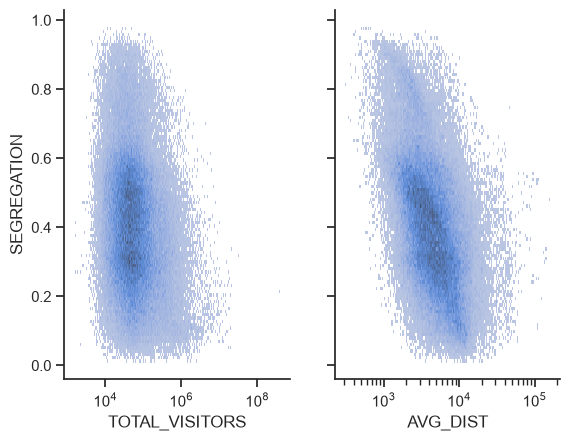

In [141]:
fig, axes = plt.subplots(1, 2, sharey=True)
sns.histplot(
    pois.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    log_scale=(True, False),
    ax=axes[0],
)
sns.histplot(
    pois.to_pandas(),
    x="AVG_DIST",
    y="SEGREGATION",
    log_scale=(True, False),
    ax=axes[1],
)
sns.despine()

## Weekly segregation

In [145]:
query = """
WITH bg AS (
    SELECT
        GEOID,
        CBSAFP,
        MEDIAN_HH_INCOME,
        NTILE(4) OVER (
            PARTITION BY CBSAFP
            ORDER BY MEDIAN_HH_INCOME
        ) AS INCOME_GROUP
    FROM block_groups_cbsa
    WHERE CBSAFP = '35620'
      AND MEDIAN_HH_INCOME IS NOT NULL
),
poi_home_summary AS (
    SELECT
        v.ID_STORE,
        v.HOME_GEOID,
        SUM(v.VISITOR_COUNTS) AS VISITOR_COUNTS,
        COUNT(*) AS NUM_WEEKS
    FROM block_group_visits v
    JOIN pois p
        ON v.ID_STORE = p.ID_STORE
    WHERE v.VISITOR_COUNTS >= 10
      AND p.CBSAFP = '35620'
    GROUP BY
        v.ID_STORE,
        v.HOME_GEOID
),
filtered_pois AS (
    SELECT ID_STORE
    FROM poi_home_summary
    WHERE NUM_WEEKS >= 20
      AND VISITOR_COUNTS >= 100
    GROUP BY ID_STORE
    HAVING COUNT(*) >= 15
),
poi_weeks AS (
    SELECT DISTINCT
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END
    FROM block_group_visits v
    WHERE v.ID_STORE IN (
        SELECT ID_STORE
        FROM filtered_pois
    )
),
poi_temperature_weekly AS (
    SELECT
        pw.ID_STORE,
        pw.DATE_RANGE_START,
        pw.DATE_RANGE_END,
        AVG(t.TMEAN) AS AVG_TMEAN,
        AVG(t.TMIN) AS AVG_TMIN,
        AVG(t.TMAX) AS AVG_TMAX,
        COUNT(t.DATE) AS NUM_TEMPERATURE_DAYS
    FROM poi_weeks pw
    JOIN pois p
        ON pw.ID_STORE = p.ID_STORE
    LEFT JOIN prism_t_daily t
        ON p.CELL_ID = t.CELL_ID
       AND t.DATE >= pw.DATE_RANGE_START
       AND t.DATE <= pw.DATE_RANGE_END
    GROUP BY
        pw.ID_STORE,
        pw.DATE_RANGE_START,
        pw.DATE_RANGE_END
),
poi_group_visits_weekly AS (
    SELECT
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END,
        bg.INCOME_GROUP,
        SUM(v.VISITOR_COUNTS) AS TOTAL_VISITORS,
        SUM(v.DIST * v.VISITOR_COUNTS) / SUM(v.VISITOR_COUNTS) AS AVG_DIST
    FROM block_group_visits_enhanced v
    JOIN bg
        ON v.HOME_GEOID = bg.GEOID
    WHERE v.ID_STORE IN (
        SELECT ID_STORE
        FROM filtered_pois
    )
    GROUP BY
        v.ID_STORE,
        v.DATE_RANGE_START,
        v.DATE_RANGE_END,
        bg.INCOME_GROUP
)
SELECT
    v.ID_STORE,
    v.DATE_RANGE_START,
    v.DATE_RANGE_END,
    v.INCOME_GROUP,
    v.TOTAL_VISITORS,
    v.AVG_DIST,
    t.AVG_TMEAN,
    t.AVG_TMIN,
    t.AVG_TMAX,
    t.NUM_TEMPERATURE_DAYS
FROM poi_group_visits_weekly v
LEFT JOIN poi_temperature_weekly t
    USING (
        ID_STORE,
        DATE_RANGE_START,
        DATE_RANGE_END
    )
ORDER BY
    v.ID_STORE,
    v.DATE_RANGE_START,
    v.INCOME_GROUP
"""
poi_group_visits_weekly = con.sql(query).pl()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [146]:
poi_dist_weekly = (
    poi_group_visits_weekly
        .group_by("ID_STORE", "DATE_RANGE_START")
        .agg(
            (
                (pl.col("AVG_DIST") * pl.col("TOTAL_VISITORS")).sum()
                / pl.col("TOTAL_VISITORS").sum()
            ).alias("AVG_DIST")
        )
)
poi_visits_weekly = (
    poi_group_visits_weekly
    .sort("INCOME_GROUP")
    .pivot(
        "INCOME_GROUP",
        index=[
            "ID_STORE",
            "DATE_RANGE_START",
            "DATE_RANGE_END",
            "AVG_TMEAN",
            "AVG_TMIN",
            "AVG_TMAX",
            "NUM_TEMPERATURE_DAYS",
        ],
        column_naming="combine",
    )
    .fill_null(
        0,
        matches_supertype=False,
    )
    .with_columns(
        pl.sum_horizontal(
            pl.selectors.starts_with("TOTAL_VISITORS_")
        ).alias("TOTAL_VISITORS")
    )
    .with_columns(
        (
            pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
            / pl.col("TOTAL_VISITORS").replace(0, None)
        ).name.replace("TOTAL_VISITORS_", "TAU_")
    )
    .with_columns(
        (
            (2 / 3)
            * pl.sum_horizontal(
                (pl.selectors.starts_with("TAU_") - 0.25).abs()
            )
        ).alias("SEGREGATION")
    )
    .filter(pl.col("TOTAL_VISITORS") > 0)
    .join(poi_dist_weekly, on=["ID_STORE", "DATE_RANGE_START"], how="left")
)

poi_visits_weekly.head()

ID_STORE,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,AVG_DIST_1,AVG_DIST_2,AVG_DIST_3,AVG_DIST_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST
str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,"decimal[38,0]",f64,f64,f64,f64,f64,f64
"""10000649""",2025-01-13 00:00:00,2025-01-19 00:00:00,0.991843,-1.919757,3.903443,7,133,165,559,331,10725.507141,11609.052197,15449.530945,13496.8771,1188,0.111953,0.138889,0.470539,0.27862,0.332211,13843.21564
"""10000649""",2025-01-20 00:00:00,2025-01-26 00:00:00,-4.750164,-8.188386,-1.311943,7,288,192,766,384,7841.479872,982.803653,19338.447511,9612.997536,1630,0.176687,0.117791,0.469939,0.235583,0.293252,12853.795308
"""10000649""",2025-01-27 00:00:00,2025-02-02 00:00:00,2.5391,-1.494314,6.572514,7,320,319,574,640,9943.845367,12850.750401,20783.305538,21905.038657,1853,0.172693,0.172153,0.309768,0.345386,0.206872,17933.22289
"""10000649""",2025-02-03 00:00:00,2025-02-09 00:00:00,1.2311,-2.633443,5.095643,7,159,314,316,737,10818.134256,5730.866111,5609.516605,20733.83501,1526,0.104194,0.205767,0.207077,0.482962,0.310616,13481.663798
"""10000649""",2025-02-10 00:00:00,2025-02-16 00:00:00,1.041257,-1.202871,3.285386,7,539,693,308,619,11765.611046,21923.76303,12568.068525,17403.683092,2159,0.249653,0.320982,0.142659,0.286707,0.143585,16757.145471


In [147]:
pois_weekly = pois_dim.join(poi_visits_weekly, on="ID_STORE")
categories_weekly = pois_weekly.group_by("CATEGORY", "DATE_RANGE_START").agg(
    pl.len().alias("NUM_POIS"),
    pl.col("SEGREGATION").mean(),
    ((pl.col("SEGREGATION") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("W_SEGREGATION"),
    pl.col("TOTAL_VISITORS").sum(),
    pl.col("TOTAL_VISITORS").mean().alias("AVG_VISITORS"),
    ((pl.col("AVG_DIST") * pl.col("TOTAL_VISITORS")).sum() / pl.col("TOTAL_VISITORS").sum()).alias("AVG_DIST"),
    pl.col("AVG_TMAX").mean()
)

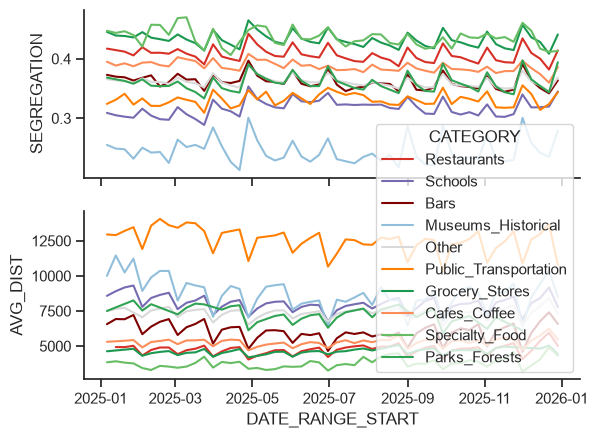

In [148]:
fig, axes = plt.subplots(2, sharex=True)
sns.lineplot(
    categories_weekly.to_pandas(),
    x="DATE_RANGE_START",
    y="SEGREGATION",
    hue="CATEGORY",
    palette=palette,
    ax=axes[0],
    legend=False
)
sns.lineplot(
    categories_weekly.to_pandas(),
    x="DATE_RANGE_START",
    y="AVG_DIST",
    hue="CATEGORY",
    palette=palette,
    ax=axes[1],
    #legend=False
)
sns.despine()

<Axes: xlabel='AVG_TMAX', ylabel='SEGREGATION'>

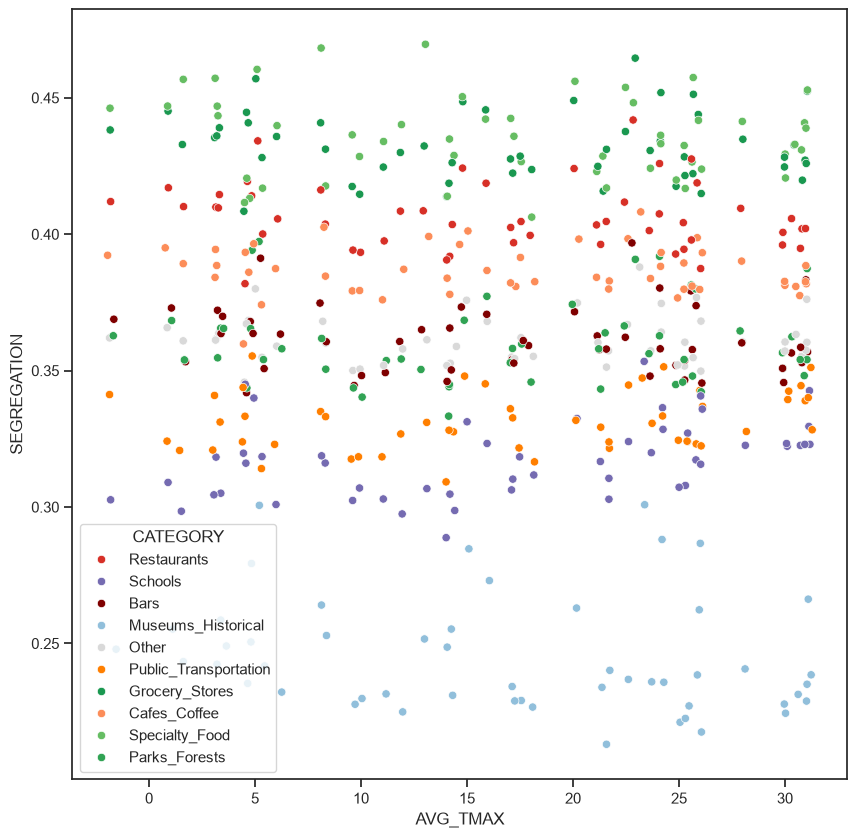

In [149]:
fig, ax = plt.subplots(figsize=(10,10))
sns.scatterplot(
    categories_weekly.to_pandas(),
    x="AVG_TMAX",
    y="SEGREGATION",
    hue="CATEGORY",
    palette=palette,
    ax=ax
)

<Axes: xlabel='AVG_TMAX', ylabel='SEGREGATION'>

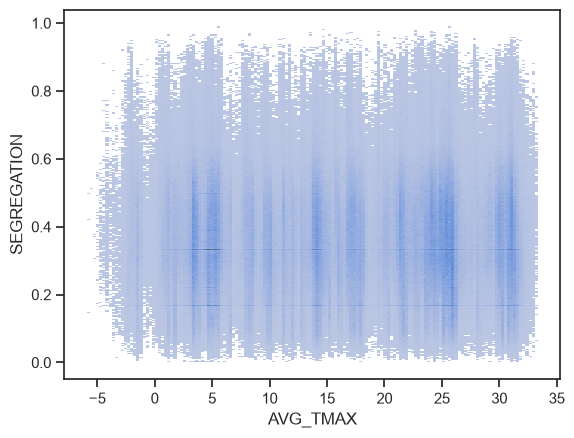

In [150]:
sns.histplot(
    pois_weekly.to_pandas(),
    x="AVG_TMAX",
    y="SEGREGATION",
)

In [156]:
pois_weekly.filter(pl.col.SEGREGATION > 0.15, pl.col.SEGREGATION < 0.17)

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,VISITORS,CATEGORY,NAICS_TITLE,DATE_RANGE_START,DATE_RANGE_END,AVG_TMEAN,AVG_TMIN,AVG_TMAX,NUM_TEMPERATURE_DAYS,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,AVG_DIST_1,AVG_DIST_2,AVG_DIST_3,AVG_DIST_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION,AVG_DIST
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",str,str,datetime[μs],datetime[μs],f64,f64,f64,i64,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,"decimal[38,0]",f64,f64,f64,f64,f64,f64
"""10000649""","""360610094002""","""35620""","""A1_NAICS-522110""","""Commercial Banking""","""Commercial Banking""","""280 Park Ave""","""New York""","""NY""","""US""","""522110""","""Depository Credit Intermediati…","""Commercial Banking """,1970-01-01,2038-01-01,-73.975514,40.756633,"b""\x01\x01\x00\x00\x00\xc7R\xda\xd1n~R\xc0\xc6\xca\x1eW\xd9`D@""",310325,145113,"""Other""","""Commercial Banking """,2025-11-24 00:00:00,2025-11-30 00:00:00,7.147207,4.157271,10.137142,7,615,688,429,387,7505.126176,11699.480124,9970.6216,7482.921355,2119,0.290231,0.324681,0.202454,0.182633,0.153217,9362.049153
"""10000649""","""360610094002""","""35620""","""A1_NAICS-522110""","""Commercial Banking""","""Commercial Banking""","""280 Park Ave""","""New York""","""NY""","""US""","""522110""","""Depository Credit Intermediati…","""Commercial Banking """,1970-01-01,2038-01-01,-73.975514,40.756633,"b""\x01\x01\x00\x00\x00\xc7R\xda\xd1n~R\xc0\xc6\xca\x1eW\xd9`D@""",310325,145113,"""Other""","""Commercial Banking """,2025-12-15 00:00:00,2025-12-21 00:00:00,1.779928,-1.959729,5.519586,7,902,401,600,553,9397.604859,8371.125371,16126.083411,13060.886123,2456,0.367264,0.163274,0.2443,0.225163,0.156352,11698.607871
"""10001264""","""360610032007""","""35620""","""A1_NAICS-238220""","""Plumbing, Heating, and Air-Con…","""Plumbing, Heating, and Air-Con…","""94 Avenue A""","""New York""","""NY""","""US""","""238220""","""Building Equipment Contractors""","""Plumbing, Heating, and Air-Con…",1970-01-01,2038-01-01,-73.983749,40.725449,"b""\x01\x01\x00\x00\x00j\x1d\x0b\xc0\xf5~R\xc0\xe9\xf6\xed\x7f\xdb\D@""",311729,518417,"""Other""","""Plumbing, Heating, and Air-Con…",2025-05-12 00:00:00,2025-05-18 00:00:00,19.198728,15.7082,22.689257,7,3113,1997,1258,2093,5401.769331,5715.317126,2845.789124,3219.453725,8461,0.367923,0.236024,0.148682,0.24737,0.157231,4555.9054
"""10001264""","""360610032007""","""35620""","""A1_NAICS-238220""","""Plumbing, Heating, and Air-Con…","""Plumbing, Heating, and Air-Con…","""94 Avenue A""","""New York""","""NY""","""US""","""238220""","""Building Equipment Contractors""","""Plumbing, Heating, and Air-Con…",1970-01-01,2038-01-01,-73.983749,40.725449,"b""\x01\x01\x00\x00\x00j\x1d\x0b\xc0\xf5~R\xc0\xe9\xf6\xed\x7f\xdb\D@""",311729,518417,"""Other""","""Plumbing, Heating, and Air-Con…",2025-06-30 00:00:00,2025-07-06 00:00:00,26.355735,21.977986,30.7342,7,1918,2894,1012,1852,2372.624647,2472.59274,2340.788471,2171.555597,7676,0.24987,0.377019,0.131839,0.241271,0.169359,2357.605049
"""10001264""","""360610032007""","""35620""","""A1_NAICS-238220""","""Plumbing, Heating, and Air-Con…","""Plumbing, Heating, and Air-Con…","""94 Avenue A""","""New York""","""NY""","""US""","""238220""","""Building Equipment Contractors""","""Plumbing, Heating, and Air-Con…",1970-01-01,2038-01-01,-73.983749,40.725449,"b""\x01\x01\x00\x00\x00j\x1d\x0b\xc0\xf5~R\xc0\xe9\xf6\xed\x7f\xdb\D@""",311729,518417,"""Other""","""Plumbing, Heating, and Air-Con…",2025-09-08 00:00:00,2025-09-14 00:00:00,20.597571,17.123572,24.071857,7,2679,2736,1356,1944,4880.757638,5239.071804,4525.837628,2195.632356,8715,0.307401,0.313941,0.155594,0.223064,0.16179,4339.070028
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…

In [154]:
pois_weekly["SEGREGATION"].value_counts().sort("count")

SEGREGATION,count
f64,u32
0.337461,1
0.285826,1
0.397394,1
0.316915,1
0.179433,1
…,…
0.5,1562
0.166667,1676
0.333333,2044


## Appendix

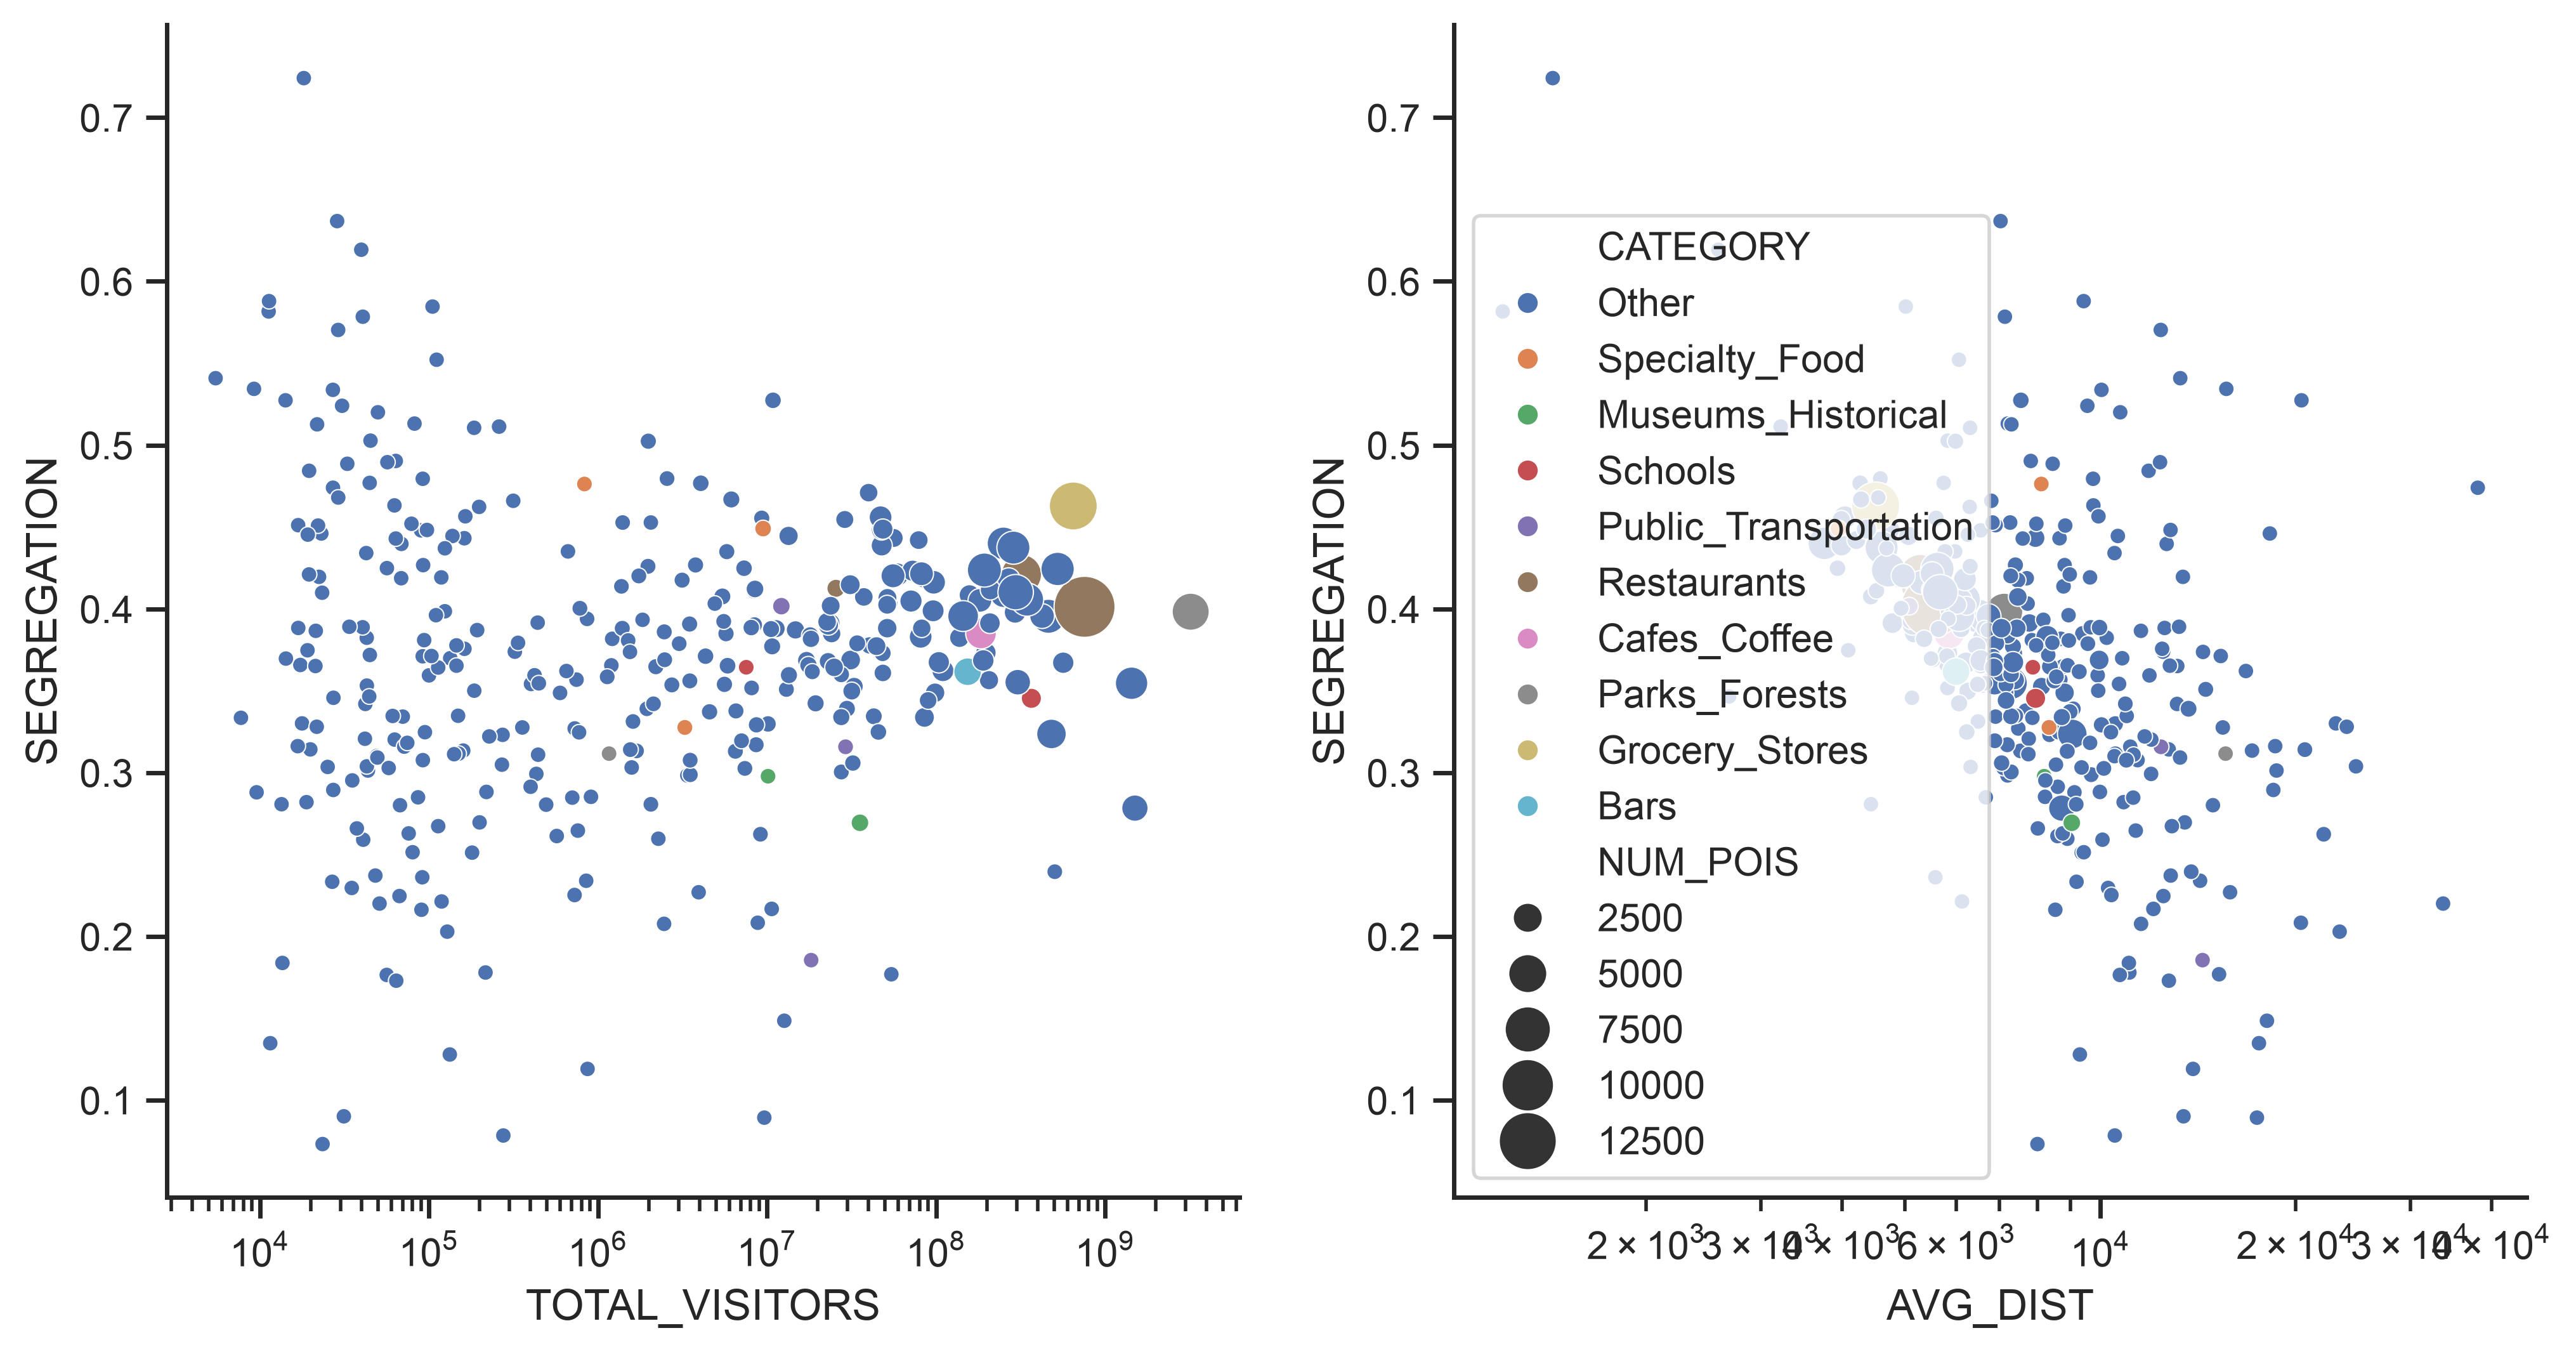

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12,6), dpi=400)
sns.scatterplot(
    categories.to_pandas(),
    x="TOTAL_VISITORS",
    y="SEGREGATION",
    hue="CATEGORY",
    size="NUM_POIS",
    sizes=(20, 300),
    ax=axes[0],
    legend=False
)
sns.scatterplot(
    categories.to_pandas(),
    x="AVG_DIST",
    y="SEGREGATION",
    hue="CATEGORY",
    size="NUM_POIS",
    sizes=(20, 300),
    ax=axes[1],
)

for ax in axes:
    ax.set_xscale("log")
sns.despine()